# 06 — Analysis (Phase 7)

Implements **exactly** the spec locked in `05_postmerge_eda_spec.ipynb` §6
(written before any model was run). Models: OLS with HC3 robust SEs.

- **M1:** `log10(domestic_gross) ~ bechdel_pass + log10(budget) + year`
- **M2:** `log10(domestic_gross) ~ pct_female_dialogue(per 10pp) + log10(budget) + year`
- Robustness R1–R4 as pre-declared. No other models.

Framing: **association, not causation.**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

INTERIM = Path.cwd().parent / "data" / "interim"
FIGS = Path.cwd().parent / "figures"

df = pd.read_csv(INTERIM / "analysis_table.csv")
df["log_dom"] = np.log10(df["domestic_gross"])
df["log_ww"] = np.log10(df["worldwide_gross"])
df["log_budget"] = np.log10(df["production_budget"])
df["pass_"] = df["bechdel_pass"].astype(int)
df["pfd_10pp"] = df["pct_female_dialogue"] * 10  # 1 unit = 10 percentage points
df["year_c"] = df["year"] - 2000                   # centered for a readable intercept

print(f"N = {len(df)}")

N = 798


## M1 — Bechdel pass (primary)

In [2]:
m1 = smf.ols("log_dom ~ pass_ + log_budget + year_c", data=df).fit(cov_type="HC3")
print(m1.summary().tables[1])
print(f"\nN = {int(m1.nobs)}, R² = {m1.rsquared:.3f}")

b = m1.params["pass_"]; lo, hi = m1.conf_int().loc["pass_"]
print(f"\nbechdel_pass: b = {b:.4f}  [95% CI {lo:.4f}, {hi:.4f}]")
print(f"as % difference in gross at fixed budget & year: "
      f"{100*(10**b - 1):+.1f}%  [CI {100*(10**lo - 1):+.1f}%, {100*(10**hi - 1):+.1f}%]")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.8572      0.306      6.078      0.000       1.258       2.456
pass_          0.0853      0.030      2.849      0.004       0.027       0.144
log_budget     0.7722      0.039     19.780      0.000       0.696       0.849
year_c        -0.0080      0.002     -3.552      0.000      -0.012      -0.004

N = 798, R² = 0.454

bechdel_pass: b = 0.0853  [95% CI 0.0266, 0.1440]
as % difference in gross at fixed budget & year: +21.7%  [CI +6.3%, +39.3%]


## M2 — Female dialogue share (secondary)

In [3]:
m2 = smf.ols("log_dom ~ pfd_10pp + log_budget + year_c", data=df).fit(cov_type="HC3")
print(m2.summary().tables[1])
print(f"\nN = {int(m2.nobs)}, R² = {m2.rsquared:.3f}")

b = m2.params["pfd_10pp"]; lo, hi = m2.conf_int().loc["pfd_10pp"]
print(f"\nper +10pp female dialogue: {100*(10**b - 1):+.1f}% gross "
      f"[CI {100*(10**lo - 1):+.1f}%, {100*(10**hi - 1):+.1f}%]")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9480      0.319      6.101      0.000       1.322       2.574
pfd_10pp       0.0028      0.009      0.323      0.747      -0.014       0.020
log_budget     0.7645      0.040     18.986      0.000       0.686       0.843
year_c        -0.0077      0.002     -3.430      0.001      -0.012      -0.003

N = 798, R² = 0.448

per +10pp female dialogue: +0.7% gross [CI -3.2%, +4.7%]


## Robustness R1–R4 (pre-declared)

In [4]:
results = {"M1 domestic": m1}

# R1: worldwide gross
results["R1 worldwide"] = smf.ols("log_ww ~ pass_ + log_budget + year_c", data=df).fit(cov_type="HC3")

# R2: Pudding inflation-adjusted domestic gross ($M, 9 missing)
r2df = df[df["gross_infl_adj_musd"] > 0].copy()
r2df["log_adj"] = np.log10(r2df["gross_infl_adj_musd"])
results["R2 infl-adj"] = smf.ols("log_adj ~ pass_ + log_budget + year_c", data=r2df).fit(cov_type="HC3")

# R3: ordinal rating (0 = reference)
r3 = smf.ols("log_dom ~ C(bechdel_rating) + log_budget + year_c", data=df).fit(cov_type="HC3")

# R4: + genre dummies (subsample with genre)
r4df = df.dropna(subset=["genre"])
results["R4 +genre"] = smf.ols("log_dom ~ pass_ + log_budget + year_c + C(genre)", data=r4df).fit(cov_type="HC3")

rows = []
for name, m in results.items():
    b = m.params["pass_"]; lo, hi = m.conf_int().loc["pass_"]
    rows.append({"model": name, "N": int(m.nobs), "R2": round(m.rsquared, 3),
                 "pass coef": round(b, 4),
                 "% gross": f"{100*(10**b-1):+.1f}%",
                 "95% CI": f"[{100*(10**lo-1):+.1f}%, {100*(10**hi-1):+.1f}%]"})
summary = pd.DataFrame(rows).set_index("model")
print(summary.to_string())

print("\nR3 — rating categories vs rating 0 (as % gross, fixed budget & year):")
for k in ["C(bechdel_rating)[T.1]", "C(bechdel_rating)[T.2]", "C(bechdel_rating)[T.3]"]:
    b = r3.params[k]; lo, hi = r3.conf_int().loc[k]
    print(f"  rating {k[-2]}: {100*(10**b-1):+6.1f}%  [{100*(10**lo-1):+.1f}%, {100*(10**hi-1):+.1f}%]")
print(f"  (R3 N = {int(r3.nobs)}, R² = {r3.rsquared:.3f})")

                N     R2  pass coef % gross           95% CI
model                                                       
M1 domestic   798  0.454     0.0853  +21.7%  [+6.3%, +39.3%]
R1 worldwide  798  0.501     0.0823  +20.9%  [+5.5%, +38.5%]
R2 infl-adj   787  0.498     0.0739  +18.5%  [+4.2%, +34.9%]
R4 +genre     711  0.419     0.0695  +17.4%  [+1.3%, +36.0%]

R3 — rating categories vs rating 0 (as % gross, fixed budget & year):
  rating 1:  +10.8%  [-21.7%, +56.8%]
  rating 2:  +58.0%  [+6.7%, +134.0%]
  rating 3:  +45.4%  [+2.5%, +106.2%]
  (R3 N = 798, R² = 0.462)


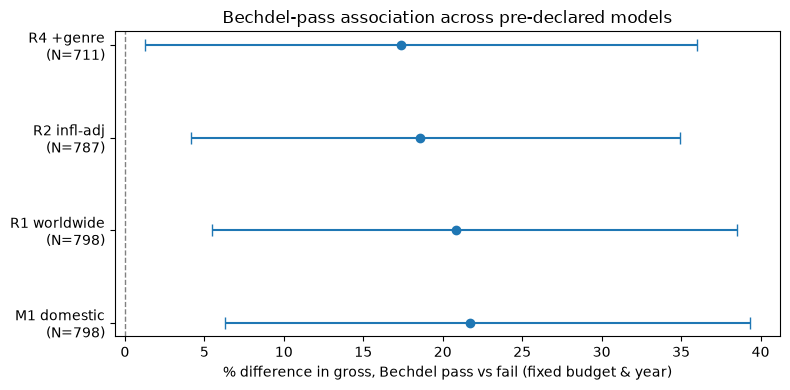

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
names, est, err_lo, err_hi = [], [], [], []
for name, m in results.items():
    b = m.params["pass_"]; lo, hi = m.conf_int().loc["pass_"]
    names.append(f"{name}\n(N={int(m.nobs)})")
    est.append(100*(10**b-1)); err_lo.append(100*(10**b-1) - 100*(10**lo-1)); err_hi.append(100*(10**hi-1) - 100*(10**b-1))
ax.errorbar(est, range(len(names)), xerr=[err_lo, err_hi], fmt="o", capsize=4)
ax.axvline(0, color="grey", lw=1, ls="--")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.set_xlabel("% difference in gross, Bechdel pass vs fail (fixed budget & year)")
ax.set_title("Bechdel-pass association across pre-declared models")
fig.tight_layout()
fig.savefig(FIGS / "analysis_pass_coefficient.png", dpi=150)
plt.show()

## Interpretation (filled 2026-07-05, post-run)

- **M1 (primary):** passing the Bechdel test is associated with **+21.7%
  domestic gross** [95% CI +6.3%, +39.3%] at fixed budget and year (p = .004,
  N = 798, R² = .454). Recall the RAW pass/fail gap was ≈ 0 (05 §4): the
  positive association only appears once budget is held fixed — the
  suppression pattern the EDA anticipated. Passing films earn more than their
  budgets predict; they are simply given smaller budgets.
- **M2 (secondary):** female dialogue *share* shows essentially no association
  (+0.7% per +10pp, CI −3.2% to +4.7%). The two predictors dissociate:
  the Bechdel threshold (women interacting, about something other than a man)
  carries the association; the sheer quantity of female speech does not.
- **Robustness:** the pass association is stable across all four pre-declared
  checks — worldwide gross (+20.9%), inflation-adjusted gross (+18.5%), genre
  controls (+17.4%), and the ordinal version (ratings 2 and 3 both elevated
  vs rating 0, though CIs are wide at the sparse low ratings — only 49
  rating-0 films).
- **Deviations from spec: none.**
- Reminder: associational estimates within a triple-selected sample of
  commercially successful films (see 05 §2 funnel); not causal effects.